# Penguins on-ice vs off-ice expected goals, 2025-26

This notebook compares Pittsburgh's expected goals for and against while each skater was on the ice and while they were on the bench. It uses MoneyPuck's Pittsburgh skater summary for the 2025-26 regular season and keeps players who appeared in at least 10 games. Every rate is per 60 minutes.

These are team results during a player's shifts or bench time. Teammates, opponents, role, and game state affect the comparison, so it does not show a player's isolated effect.


## What the measures mean

- **xGoals For (xGF):** Pittsburgh's expected goals while the player was on the ice or on the bench.
- **xGoals Against (xGA):** opponents' expected goals during those minutes.
- **Relative xGF/60:** on-ice xGF/60 minus off-ice xGF/60. Positive means Pittsburgh generated xGoals at a higher rate with the player on the ice.
- **Relative xGA/60:** on-ice xGA/60 minus off-ice xGA/60. Negative means opponents generated xGoals at a lower rate with the player on the ice.

MoneyPuck credits on-ice and off-ice events based on whether the player was playing or on the bench. See the [MoneyPuck glossary](https://www.moneypuck.com/glossary.htm).


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / 'data').exists():
    PROJECT_DIR = PROJECT_DIR.parent
latest_file = PROJECT_DIR / 'data' / 'moneypuck_pit_2025_26_skaters_latest.csv'
raw_file = PROJECT_DIR / 'data' / 'moneypuck_pit_2025_26_skaters_raw.csv'
DATA_FILE = latest_file if latest_file.exists() else raw_file
SOURCE_URL = 'https://moneypuck.com/moneypuck/playerData/seasonSummary/2025/regular/teams/skaters/PIT.csv'
raw = pd.read_csv(DATA_FILE)
print('MoneyPuck source:', SOURCE_URL)
print('Saved data file:', DATA_FILE.name)
print(f'File contains {len(raw)} rows and {len(raw.columns)} columns.')


MoneyPuck source: https://moneypuck.com/moneypuck/playerData/seasonSummary/2025/regular/teams/skaters/PIT.csv
Saved data file: moneypuck_pit_2025_26_skaters_latest.csv
File contains 190 rows and 154 columns.


## 1. Inspect the relevant source columns

MoneyPuck stores a separate row for each player and situation. The `all` row combines situations, so we use it once per player. The source includes on-ice and off-ice xGoals plus the time spent on ice and on the bench.


In [2]:
print('Situations in the file:', ', '.join(sorted(raw['situation'].dropna().unique())))
preview_columns = ['name', 'position', 'situation', 'games_played', 'icetime', 'timeOnBench',
                   'OnIce_F_xGoals', 'OffIce_F_xGoals', 'OnIce_A_xGoals', 'OffIce_A_xGoals']
raw[preview_columns].head(8)


Situations in the file: 4on5, 5on4, 5on5, all, other


,name,position,situation,games_played,icetime,timeOnBench,OnIce_F_xGoals,OffIce_F_xGoals,OnIce_A_xGoals,OffIce_A_xGoals
0,Kevin Hayes,R,other,28,287.0,1433.0,0.08,5.95,1.51,5.55
1,Kevin Hayes,R,all,28,20956.0,81616.0,16.22,68.19,13.66,74.93
2,Kevin Hayes,R,5on5,28,18841.0,64738.0,13.98,45.35,11.22,45.14
3,Kevin Hayes,R,4on5,28,2.0,470.0,0.00,0.10,0.00,0.82
4,Kevin Hayes,R,5on4,28,1826.0,4035.0,2.15,8.96,0.84,1.46
5,Sam Poulin,R,other,2,0.0,0.0,0.00,0.00,0.00,0.00
6,Sam Poulin,R,all,2,1658.0,5792.0,0.81,5.02,0.80,3.12
7,Sam Poulin,R,5on5,2,1589.0,4456.0,0.81,2.65,0.76,2.58


## 2. Calculate each player's on-ice and off-ice rates

The source records `icetime` and `timeOnBench` in seconds. We convert each to minutes, divide the matching xGoals total by those minutes, and scale to 60. The only playing-time filter is at least 10 games.


In [3]:
players = raw.loc[raw['situation'].eq('all')].copy()
numeric_columns = ['games_played', 'icetime', 'timeOnBench', 'OnIce_F_xGoals', 'OffIce_F_xGoals', 'OnIce_A_xGoals', 'OffIce_A_xGoals']
players[numeric_columns] = players[numeric_columns].apply(pd.to_numeric, errors='raise')
players['On-ice minutes'] = players['icetime'] / 60
players['Off-ice minutes'] = players['timeOnBench'] / 60
eligible = players.loc[players['games_played'].ge(10) & players['On-ice minutes'].gt(0) & players['Off-ice minutes'].gt(0)].copy()

eligible['xGF on per 60'] = eligible['OnIce_F_xGoals'] / eligible['On-ice minutes'] * 60
eligible['xGF off per 60'] = eligible['OffIce_F_xGoals'] / eligible['Off-ice minutes'] * 60
eligible['Relative xGF per 60'] = eligible['xGF on per 60'] - eligible['xGF off per 60']
eligible['xGA on per 60'] = eligible['OnIce_A_xGoals'] / eligible['On-ice minutes'] * 60
eligible['xGA off per 60'] = eligible['OffIce_A_xGoals'] / eligible['Off-ice minutes'] * 60
eligible['Relative xGA per 60'] = eligible['xGA on per 60'] - eligible['xGA off per 60']

result = eligible[['name', 'position', 'games_played', 'On-ice minutes', 'Off-ice minutes',
    'OnIce_F_xGoals', 'OffIce_F_xGoals', 'xGF on per 60', 'xGF off per 60', 'Relative xGF per 60',
    'OnIce_A_xGoals', 'OffIce_A_xGoals', 'xGA on per 60', 'xGA off per 60', 'Relative xGA per 60']].copy()
result = result.rename(columns={'name':'Player', 'position':'Position', 'games_played':'Games',
    'OnIce_F_xGoals':'xGF on total', 'OffIce_F_xGoals':'xGF off total',
    'OnIce_A_xGoals':'xGA on total', 'OffIce_A_xGoals':'xGA off total'})
result = result.sort_values('Relative xGF per 60', ascending=False).reset_index(drop=True)
result.insert(0, 'Rank by relative xGF/60', range(1, len(result) + 1))
result[result.select_dtypes(include='number').columns] = result.select_dtypes(include='number').round(2)
result.to_csv(PROJECT_DIR / 'data' / 'penguins_on_off_xgoals_2025_26.csv', index=False)
print(f'Eligible players: {len(result)} of {len(players)} all-situations players.')
print('Table saved to data/penguins_on_off_xgoals_2025_26.csv')
display(result)


Eligible players: 29 of 38 all-situations players.
Table saved to data/penguins_on_off_xgoals_2025_26.csv


,Rank by relative xGF/60,Player,Position,Games,On-ice minutes,Off-ice minutes,xGF on total,xGF off total,xGF on per 60,xGF off per 60,Relative xGF per 60,xGA on total,xGA off total,xGA on per 60,xGA off per 60,Relative xGA per 60
0,1,Evgeni Malkin,C,56,985.25,2421.02,76.70,109.70,4.67,2.72,1.95,49.12,121.21,2.99,3.00,-0.01
1,2,Bryan Rust,R,72,1436.00,2967.53,101.03,137.63,4.22,2.78,1.44,82.10,148.91,3.43,3.01,0.42
2,3,Rickard Rakell,R,60,1136.92,2520.73,79.11,121.49,4.17,2.89,1.28,66.65,130.28,3.52,3.10,0.42
3,4,Sidney Crosby,C,68,1307.70,2840.55,91.06,137.95,4.18,2.91,1.26,67.95,141.10,3.12,2.98,0.14
4,5,Erik Karlsson,D,75,1770.03,2803.50,114.96,135.65,3.90,2.90,0.99,93.81,143.35,3.18,3.07,0.11
5,6,Anthony Mantha,R,81,1230.17,3713.37,77.47,192.35,3.78,3.11,0.67,60.34,193.83,2.94,3.13,-0.19
6,7,Ben Kindel,C,77,1159.87,3538.67,68.48,190.41,3.54,3.23,0.31,53.50,186.85,2.77,3.17,-0.40
7,8,Egor Chinakhov,R,72,970.55,3442.57,54.07,181.49,3.34,3.16,0.18,47.53,189.52,2.94,3.30,-0.36
8,9,Tommy Novak,C,82,1171.07,3832.47,65.70,206.70,3.37,3.24,0.13,50.35,208.83,2.58,3.27,-0.69
9,10,Kris Letang,D,74,1604.50,2918.17,89.07,159.68,3.33,3.28,0.05,92.05,143.77,3.44,2.96,0.49


## 3. Check the calculations

These checks confirm that the comparison uses one all-situations row per player, applies the 10-game minimum, has recorded on-ice and bench time, and calculates relative rates as on ice minus off ice.


In [4]:
checks = {
    'One all-situations row per eligible player': bool(eligible['name'].is_unique),
    'Every player meets the 10-game minimum': bool(eligible['games_played'].ge(10).all()),
    'On-ice and bench time are positive': bool((eligible['On-ice minutes'].gt(0) & eligible['Off-ice minutes'].gt(0)).all()),
    'Relative xGF/60 matches on ice minus off ice': bool((eligible['Relative xGF per 60'] - (eligible['xGF on per 60'] - eligible['xGF off per 60'])).abs().lt(1e-9).all()),
    'Relative xGA/60 matches on ice minus off ice': bool((eligible['Relative xGA per 60'] - (eligible['xGA on per 60'] - eligible['xGA off per 60'])).abs().lt(1e-9).all()),
}
for description, passed in checks.items():
    print(f'{description}: {passed}')
assert all(checks.values()), 'Please inspect the source data before interpreting the comparison.'


One all-situations row per eligible player: True
Every player meets the 10-game minimum: True
On-ice and bench time are positive: True
Relative xGF/60 matches on ice minus off ice: True
Relative xGA/60 matches on ice minus off ice: True


## 4. Compare the rates visually

Each line joins a player's on-ice and off-ice rate. Higher xGF is better for Pittsburgh; lower xGA is better for Pittsburgh. The connector shows the direction and size of the difference.


Chart saved to data\penguins_on_off_xgoals_2025_26.png


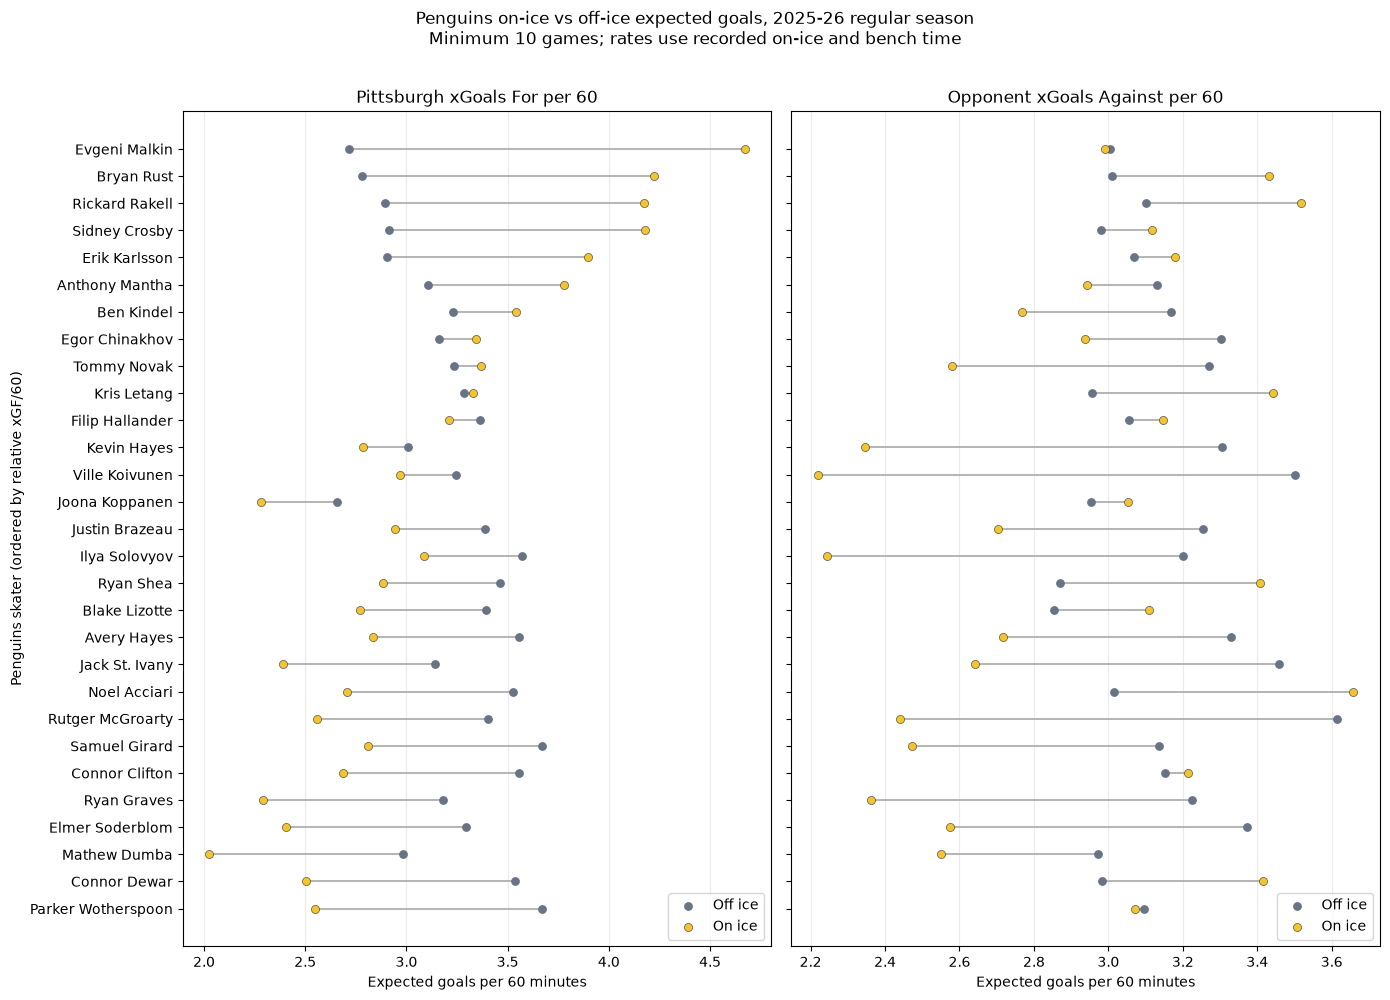

In [5]:
chart = eligible.sort_values('Relative xGF per 60', ascending=True).reset_index(drop=True)
y_positions = list(range(len(chart)))
fig, axes = plt.subplots(1, 2, figsize=(14, max(9, len(chart) * 0.34)), sharey=True)
panels = [('xGF on per 60', 'xGF off per 60', 'Pittsburgh xGoals For per 60'),
          ('xGA on per 60', 'xGA off per 60', 'Opponent xGoals Against per 60')]
for ax, (on_col, off_col, title) in zip(axes, panels):
    for y, (_, row) in zip(y_positions, chart.iterrows()):
        ax.plot([row[off_col], row[on_col]], [y, y], color='#a8a8a8', linewidth=1.2, zorder=1)
    ax.scatter(chart[off_col], y_positions, color='#687386', label='Off ice', s=28, zorder=2)
    ax.scatter(chart[on_col], y_positions, color='#f4c430', edgecolor='#333333', linewidth=0.4, label='On ice', s=34, zorder=3)
    ax.set_title(title)
    ax.set_xlabel('Expected goals per 60 minutes')
    ax.grid(axis='x', alpha=0.25)
    ax.legend(loc='lower right')
axes[0].set_yticks(y_positions, chart['name'].str.strip())
axes[0].set_ylabel('Penguins skater (ordered by relative xGF/60)')
fig.suptitle('Penguins on-ice vs off-ice expected goals, 2025-26 regular season\nMinimum 10 games; rates use recorded on-ice and bench time', y=1.01)
fig.tight_layout()
chart_path = PROJECT_DIR / 'data' / 'penguins_on_off_xgoals_2025_26.png'
fig.savefig(chart_path, dpi=160, bbox_inches='tight')
print(f'Chart saved to {chart_path.relative_to(PROJECT_DIR)}')
plt.show()


## 5. Interpretation and source credit

Positive relative xGF/60 means Pittsburgh generated expected goals at a higher rate with that player on the ice. Negative relative xGA/60 means opponents generated expected goals at a lower rate with that player on the ice. These comparisons are affected by line combinations, opponents, score, and role; they do not prove an individual caused the difference.

MoneyPuck asks users to clearly credit its data when showing results. See its [download page](https://www.moneypuck.com/data.htm). This notebook uses the saved CSV, so it runs without an internet connection.
